In [13]:
%%writefile fizzbuzz.py
'''
Prints numbers from 1 to 100 (both included). 
It replaces the numbers divisible by 3 with the string "Fizz"
It replaces the numbers divisible by 5with the string "Fizz"
Changed to test github
'''

import sys

def div_by_3(number):
    if number % 3 == 0:
        return True
    else:
        return False
        
def div_by_5(number):
    if number % 5 == 0:
        return True
    else:
        return False


def main():
    i = 1
    while i <= 100:
        if div_by_3(i) and div_by_5(i):
            print("FizzBuzz")
        elif div_by_3(i):
            print("Fizz")
        elif div_by_5(i):
            print("Buzz")
        else:
            print(i)
        i += 1
if __name__ == "__main__":
    main()


Overwriting fizzbuzz.py


In [14]:
%run fizzbuzz.py

1
2
Fizz
4
Buzz
Fizz
7
8
Fizz
Buzz
11
Fizz
13
14
FizzBuzz
16
17
Fizz
19
Buzz
Fizz
22
23
Fizz
Buzz
26
Fizz
28
29
FizzBuzz
31
32
Fizz
34
Buzz
Fizz
37
38
Fizz
Buzz
41
Fizz
43
44
FizzBuzz
46
47
Fizz
49
Buzz
Fizz
52
53
Fizz
Buzz
56
Fizz
58
59
FizzBuzz
61
62
Fizz
64
Buzz
Fizz
67
68
Fizz
Buzz
71
Fizz
73
74
FizzBuzz
76
77
Fizz
79
Buzz
Fizz
82
83
Fizz
Buzz
86
Fizz
88
89
FizzBuzz
91
92
Fizz
94
Buzz
Fizz
97
98
Fizz
Buzz


In [72]:
import random as rdom

import numpy as np

operations = [2,3]

n_iter = 0
curr_number = rdom.randrange(1,21)
curr_number = curr_number ** rdom.choice(operations)
largest = curr_number
smallest = curr_number
prev_number = 21
while curr_number % prev_number != 0:
    prev_number = curr_number
    curr_number = rdom.randrange(1,21)
    curr_number = curr_number ** rdom.choice(operations)
    if curr_number > largest:
        largest = curr_number
    elif curr_number < smallest:
        smallest = curr_number
    n_iter += 1
    

print(f"The smallest number is {smallest} and the largest is {largest}")
print(f"The loop was broken because {curr_number} is divisible by {prev_number}")
print(f"Finished after {n_iter} iterations")



The smallest number is 4 and the largest is 729
The loop was broken because 324 is divisible by 4
Finished after 5 iterations


In [70]:
4096 % 8

0

In [31]:
%%writefile spectrum.py

import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def read_data(filename):
    wavelength = []
    intensity = []

    with open(filename, 'r') as file:
        for line in file:
            # Ignore empty lines
            if not line.strip():
                continue

            columns = line.split()

            wavelength.append(float(columns[0]))
            intensity.append(float(columns[1]))

    return wavelength, intensity

def _get_axes(ax):
    """Return (ax, standalone). standalone=True means this call created its
    own figure and is responsible for finishing it off (legend + show)."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 4))
        return ax, True
    return ax, False

def gaussian(x, amplitude, center, sigma):
    return amplitude * np.exp(-(x - center) ** 2 / (2 * sigma ** 2))

def first_plot(data, ax=None):
    ax, standalone = _get_axes(ax)
    ax.scatter(data[0], data[1], s=10, color="tab:blue", label="Spectrum")
    ax.set_xlabel("Wavelength (Å)")
    ax.set_ylabel("Energy")
    if standalone:
        ax.legend()
        plt.show()
    return ax

def second_plot(data, ax=None, degree=3, sigma=2.5, iterations=4):
    """Plot the full spectrum with a polynomial baseline fit overlaid in red.

    The fit uses iterative sigma-clipping: it fits a polynomial, throws out
    points that sit more than `sigma` standard deviations *above* the fit
    (i.e. emission features), and refits on what's left. That way it finds
    the continuum/baseline automatically without needing to be told where
    the emission line is.
    """
    ax, standalone = _get_axes(ax)
    first_plot(data, ax=ax)

    wavelength = np.array(data[0])
    intensity = np.array(data[1])

    mask = np.ones_like(wavelength, dtype=bool)
    for _ in range(iterations):
        coeffs, cov = np.polyfit(wavelength[mask], intensity[mask], degree, cov=True)
        baseline = np.polyval(coeffs, wavelength)
        residual = intensity - baseline
        std = residual[mask].std()
        mask = residual < sigma * std

    # Final fit on the converged baseline mask
    coeffs, cov = np.polyfit(wavelength[mask], intensity[mask], degree, cov=True)
    baseline = np.polyval(coeffs, wavelength)
    coeff_errors = np.sqrt(np.diag(cov))

    ax.plot(wavelength, baseline, color="red", linewidth=2, label="Baseline fit")

    if standalone:
        ax.legend()
        plt.show()

    return {
        "wavelength": wavelength,
        "intensity": intensity,
        "coeffs": coeffs,
        "coeff_errors": coeff_errors,
        "baseline": baseline,
        "mask": mask,
    }

def third_plot(data, ax=None, degree=3, sigma=2.5, iterations=4):
    """Plot the full spectrum, the polynomial baseline fit, and a Gaussian
    fit to the emission peak (baseline + Gaussian, overlaid in green).

    The points second_plot flagged as "not baseline" are treated as the
    emission line and used to fit the Gaussian.
    """
    ax, standalone = _get_axes(ax)
    fit = second_plot(data, ax=ax, degree=degree, sigma=sigma, iterations=iterations)

    wavelength = fit["wavelength"]
    intensity = fit["intensity"]
    mask = fit["mask"]
    baseline = fit["baseline"]

    line_wavelength = wavelength[~mask]
    line_residual = (intensity - baseline)[~mask]

    p0 = [line_residual.max(), line_wavelength[np.argmax(line_residual)], 1.0]
    popt, pcov = curve_fit(gaussian, line_wavelength, line_residual, p0=p0)
    perr = np.sqrt(np.diag(pcov))

    # Evaluate on a fine grid so the peak looks smooth rather than polygonal
    fine_wavelength = np.linspace(wavelength.min(), wavelength.max(), 1000)
    fine_curve = np.polyval(fit["coeffs"], fine_wavelength) + gaussian(fine_wavelength, *popt)
    ax.plot(fine_wavelength, fine_curve, color="green", linewidth=2, label="Baseline + Gaussian")

    if standalone:
        ax.legend()
        plt.show()

    fit.update({"gaussian_params": popt, "gaussian_errors": perr})
    return fit

def main(filename):
    data = read_data(filename)

    first_plot(data)

    baseline_fit = second_plot(data)
    degree = len(baseline_fit["coeffs"]) - 1
    print("Polynomial baseline fit:")
    for power, c, e in zip(range(degree, -1, -1), baseline_fit["coeffs"], baseline_fit["coeff_errors"]):
        print(f"  a{power} = {c:.6g} +/- {e:.2g}")

    full_fit = third_plot(data)
    amplitude, center, fit_sigma = full_fit["gaussian_params"]
    amplitude_err, center_err, fit_sigma_err = full_fit["gaussian_errors"]
    print("Gaussian emission-line fit:")
    print(f"  amplitude = {amplitude:.6g} +/- {amplitude_err:.2g}")
    print(f"  center    = {center:.6g} +/- {center_err:.2g} Å")
    print(f"  sigma     = {fit_sigma:.6g} +/- {fit_sigma_err:.2g} Å")

if __name__ == '__main__':
    # main()
    # or get the arguments here
    args = sys.argv[1:]
    main(args[0])

Overwriting spectrum.py


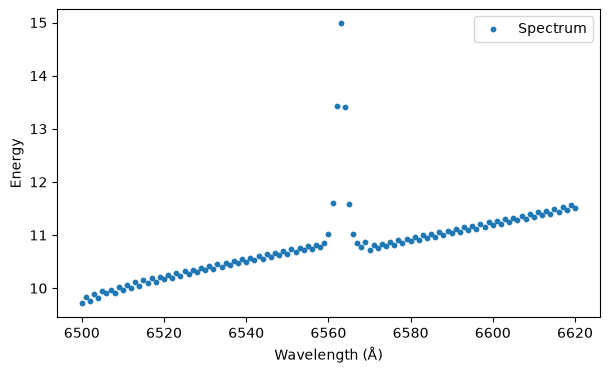

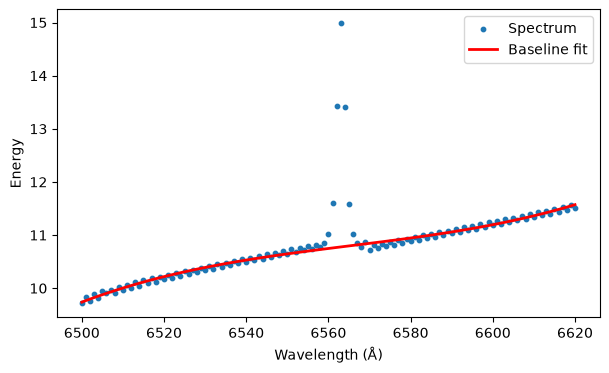

Polynomial baseline fit:
  a3 = 1.53076e-06 +/- 1.4e-07
  a2 = -0.0301511 +/- 0.0027
  a1 = 197.97 +/- 18
  a0 = -433295 +/- 3.9e+04


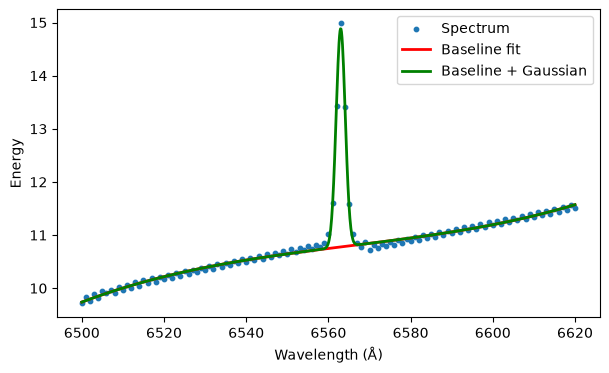

Gaussian emission-line fit:
  amplitude = 4.10993 +/- 0.12
  center    = 6562.99 +/- 0.036 Å
  sigma     = 1.10204 +/- 0.036 Å


In [32]:
%run spectrum.py "spectrum.txt"